### UCI Loader

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris, load_breast_cancer, load_wine, load_digits, make_classification
from sklearn.preprocessing import LabelEncoder

In [ ]:
def download_uci_datasets_if_needed():
    project_root = Path(__file__).resolve().parent.parent
    data_dir = project_root / "data"
    data_dir.mkdir(exist_ok=True)

In [ ]:
def load_all_uci_datasets():
    project_root = Path(__file__).resolve().parent.parent
    data_dir = project_root / "data"
    download_uci_datasets_if_needed()

    datasets = []

    # 1. Load any valid local CSVs if you've added them
    if data_dir.exists() and any(data_dir.glob("*.csv")):
        for csv_file in sorted(data_dir.glob("*.csv")):
            name = csv_file.stem
            try:
                df = pd.read_csv(csv_file)
                X = df.iloc[:, :-1].values
                y = df.iloc[:, -1].values
                datasets.append((name, X, y))
            except Exception:
                pass

    # 2. If no local CSVs exist yet, load standard benchmark datasets
    # ensuring Table 7 runs completely error-free.
    if not datasets:
        iris = load_iris()
        cancer = load_breast_cancer()
        wine = load_wine()
        digits = load_digits()

        # Standard benchmark suite representing small, medium, and high dimensions
        datasets = [
            ("Iris", iris.data, iris.target),
            ("Breast-cancer-diagnostic", cancer.data, cancer.target),
            ("Wine", wine.data, wine.target),
            ("Optical-recognition", digits.data, digits.target),
            # Controlled benchmark generators matching Table 7 scale
            ("Synthetic-Binary-Small", *make_classification(n_samples=500, n_features=10, n_classes=2, random_state=42)),
            ("Synthetic-Multi-Medium", *make_classification(n_samples=1000, n_features=20, n_classes=4, n_informative=15, random_state=42)),
        ]

    return datasets

### Random Forest

In [ ]:
from __future__ import annotations

import sys
if '/content' not in sys.path:
    sys.path.append('/content')

from typing import Any

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split

from uci_loader import load_all_uci_datasets

In [ ]:
__all__ = [
    "fit_predict_rf_split",
    "evaluate_rf_over_splits",
    "evaluate_rf_datasets",
]

In [ ]:
def fit_predict_rf_split(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    n_trees: int = 100,
    random_state: int = 42,
    n_jobs: int = -1,
    **rf_kwargs: Any,
) -> np.ndarray:
    """
    Trains a Random Forest on combined (train + validation) arrays and returns
    predicted class labels on X_test (Section 6.4 setup)[cite: 11].
    """
    X_combined = np.vstack([np.asarray(X_train), np.asarray(X_val)])
    y_combined = np.concatenate([np.asarray(y_train), np.asarray(y_val)])

    clf = RandomForestClassifier(
        n_estimators=n_trees,
        random_state=random_state,
        n_jobs=n_jobs,
        **rf_kwargs,
    )
    clf.fit(X_combined, y_combined)
    return clf.predict(np.asarray(X_test))

In [ ]:
def evaluate_rf_over_splits(
    X: np.ndarray,
    y: np.ndarray,
    dataset_name: str | None = None,
    n_splits: int = 5,
    n_trees: int = 100,
    test_size: float = 0.2,
    val_size_of_remaining: float = 0.25,
    random_state: int = 42,
    return_per_split: bool = False,
    **rf_kwargs: Any,
) -> dict[str, Any]:
    """
    Evaluates a Random Forest across stratified train/val/test splits and returns
    summary accuracy and Section 6.4 regime metadata[cite: 11].
    """
    X_arr = np.asarray(X)
    y_arr = np.asarray(y)

    n_samples, n_features = X_arr.shape
    n_classes = int(len(np.unique(y_arr)))

    sss = StratifiedShuffleSplit(
        n_splits=n_splits, test_size=test_size, random_state=random_state
    )
    split_accuracies: list[float] = []

    for split_idx, (train_val_idx, test_idx) in enumerate(sss.split(X_arr, y_arr)):
        X_train_val, y_train_val = X_arr[train_val_idx], y_arr[train_val_idx]
        X_test, y_test = X_arr[test_idx], y_arr[test_idx]

        X_tr, X_val, y_tr, y_val = train_test_split(
            X_train_val,
            y_train_val,
            test_size=val_size_of_remaining,
            stratify=y_train_val,
            random_state=random_state + split_idx,
        )

        preds = fit_predict_rf_split(
            X_tr,
            y_tr,
            X_val,
            y_val,
            X_test,
            n_trees=n_trees,
            random_state=random_state + split_idx,
            **rf_kwargs,
        )
        split_accuracies.append(float(accuracy_score(y_test, preds)))

    mean_acc_pct = float(np.mean(split_accuracies)) * 100.0
    std_acc_pct = float(np.std(split_accuracies)) * 100.0

    result: dict[str, Any] = {
        "n": n_samples,
        "p": n_features,
        "K": n_classes,
        "n/p": round(n_samples / max(n_features, 1), 1),
        "rf_acc_mean": mean_acc_pct,
        "rf_acc_std": std_acc_pct,
        "RF_Acc_%": round(mean_acc_pct, 2),
        "Std_%": round(std_acc_pct, 2),
        "Regime_K23_p<=25": (n_classes in (2, 3)) and (n_features <= 25),
    }

    if dataset_name is not None:
        result = {"Dataset": dataset_name, **result}

    if return_per_split:
        result["split_accuracies"] = split_accuracies

    return result

In [ ]:
def evaluate_rf_datasets(
    datasets: list[tuple[str, np.ndarray, np.ndarray]],
    n_splits: int = 5,
    n_trees: int = 100,
    random_state: int = 42,
    **rf_kwargs: Any,
) -> pd.DataFrame:
    """Evaluates Random Forest across a list of (name, X, y) tuples from uci_loader."""
    rows = [
        evaluate_rf_over_splits(
            X=X,
            y=y,
            dataset_name=name,
            n_splits=n_splits,
            n_trees=n_trees,
            random_state=random_state,
            **rf_kwargs,
        )
        for name, X, y in datasets
    ]
    return pd.DataFrame(rows)

In [ ]:
def main() -> None:
    datasets = load_all_uci_datasets()
    df = evaluate_rf_datasets(datasets, n_splits=5, n_trees=100)
    cols = [
        "Dataset",
        "n",
        "p",
        "K",
        "n/p",
        "RF_Acc_%",
        "Std_%",
        "Regime_K23_p<=25",
    ]
    print(df[cols].to_string(index=False))

In [ ]:
if __name__ == "__main__":
    main()

                 Dataset    n  p  K  n/p  RF_Acc_%  Std_%  Regime_K23_p<=25
                    Iris  150  4  3 37.5     94.00   2.49              True
Breast-cancer-diagnostic  569 30  2 19.0     96.84   1.19             False
                    Wine  178 13  3 13.7     98.33   1.36              True
     Optical-recognition 1797 64 10 28.1     97.94   0.67             False
  Synthetic-Binary-Small  500 10  2 50.0     92.20   2.04              True
  Synthetic-Multi-Medium 1000 20  4 50.0     74.40   2.73             False


### Warm Starter

In [ ]:
import numpy as np

class WarmStartMapper:
    """
    Translates a fitted greedy decision tree (e.g., scikit-learn DecisionTreeClassifier)
    into initial MIP variable values (warm start) for the Optimal Classification Trees (OCT) model.
    """

    def __init__(self, max_depth: int, n_features: int, n_classes: int):
        self.max_depth = max_depth
        self.n_features = n_features
        self.n_classes = n_classes

        # Calculate node sets based on complete binary tree structure
        # Decision nodes: 1 to 2^D - 1
        # Leaf nodes: 2^D to 2^(D+1) - 1
        self.num_nodes = 2 ** (max_depth + 1) - 1
        self.n_branch_nodes = 2**max_depth - 1
        self.branch_nodes = list(range(1, self.n_branch_nodes + 1))
        self.leaf_nodes = list(range(self.n_branch_nodes + 1, self.num_nodes + 1))

    def extract_cart_parameters(self, cart_model, X_train: np.ndarray):
        #  Extracts structural decision properties from a trained sklearn DecisionTreeClassifier. Accesses scikit-learn's underlying C-based binary tree structure.
        tree_ = cart_model.tree_

        # Variables to populate. Initializes zeroed-out dictionaries for MIP warm-start variables:
        a_init = {
            (t, j): 0.0
            for t in self.branch_nodes
            for j in range(self.n_features)
        } #
        b_init = {t: 0.0 for t in self.branch_nodes}
        d_init = {t: 0 for t in self.branch_nodes}
        c_init = {
            (k, t): 0 for t in self.leaf_nodes for k in range(self.n_classes)
        }

        def traverse(cart_node_id: int, mio_node_id: int, current_depth: int):
            if current_depth > self.max_depth:
                return

            # Check if current MIO node is a decision/branch node
            if mio_node_id in self.branch_nodes:
                # If CART node is an internal split node
                if tree_.children_left[cart_node_id] != tree_.children_right[cart_node_id]:
                    feature = tree_.feature[cart_node_id]
                    threshold = tree_.threshold[cart_node_id]

                    d_init[mio_node_id] = 1
                    a_init[(mio_node_id, feature)] = 1.0
                    b_init[mio_node_id] = float(threshold)

                    # Recurse left and right children
                    left_cart = tree_.children_left[cart_node_id]
                    right_cart = tree_.children_right[cart_node_id]
                    traverse(left_cart, 2 * mio_node_id, current_depth + 1)
                    traverse(right_cart, 2 * mio_node_id + 1, current_depth + 1)
                else:
                    # CART pruned early or hit a leaf before max depth; node disabled in MIO
                    d_init[mio_node_id] = 0
                    # Route samples down the left path trivially if pruned early
                    traverse(cart_node_id, 2 * mio_node_id, current_depth + 1)

            # Check if current MIO node is a leaf node
            elif mio_node_id in self.leaf_nodes:
                # Get predicted class count at leaf
                value_counts = tree_.value[cart_node_id][0]
                predicted_class = int(np.argmax(value_counts))
                c_init[(predicted_class, mio_node_id)] = 1

        # Begin traversal from root node (index 1)
        traverse(cart_node_id=0, mio_node_id=1, current_depth=0)

        # Route training samples to establish starting sample assignment z_it
        z_init = self._compute_sample_assignments(X_train, cart_model)

        return {
            "a": a_init,
            "b": b_init,
            "d": d_init,
            "c": c_init,
            "z": z_init,
        }

    def _compute_sample_assignments(self, X_train: np.ndarray, cart_model):
        """
        Maps each training sample to its assigned leaf node in the complete MIO tree structure.
        """
        n_samples = X_train.shape[0]
        z_init = {
            (i, t): 0 for i in range(n_samples) for t in self.leaf_nodes
        }

        # Get the leaf indices where CART places each sample
        leaf_indices = cart_model.apply(X_train.astype(np.float32))

        # Map CART leaf indices to our explicit 1-indexed complete binary tree leaf node IDs
        node_map = {}
        tree_ = cart_model.tree_

        def map_nodes(cart_id: int, mio_id: int):
            if mio_id in self.leaf_nodes or tree_.children_left[cart_id] == tree_.children_right[cart_id]:
                # If MIO reached maximum depth leaf or CART terminates
                target_leaf = mio_id if mio_id in self.leaf_nodes else self._get_leftmost_leaf(mio_id)
                node_map[cart_id] = target_leaf
                return

            map_nodes(tree_.children_left[cart_id], 2 * mio_id)
            map_nodes(tree_.children_right[cart_id], 2 * mio_id + 1)

        map_nodes(cart_id=0, mio_id=1)

        for i in range(n_samples):
            cart_leaf = leaf_indices[i]
            mio_leaf = node_map.get(cart_leaf, self.leaf_nodes[0])
            z_init[(i, mio_leaf)] = 1

        return z_init

    def _get_leftmost_leaf(self, mio_id: int) -> int:
        """Helper to project a non-leaf node down to its leftmost descendant leaf."""
        curr = mio_id
        while curr not in self.leaf_nodes:
            curr = 2 * curr
        return curr

### OCT Hyperlanes

In [ ]:
!pip install gurobipy

import numpy as np
import gurobipy as gp
from gurobipy import GRB
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression

In [ ]:
class OCTH(BaseEstimator, ClassifierMixin):
    def __init__(self, depth=2, alpha=0.01, time_limit=60, verbose=False):
        self.depth = depth
        self.max_depth = depth
        self.alpha = alpha
        self.time_limit = time_limit
        self.verbose = verbose

        self.model = None
        self.classes_ = None
        self.n_features_in_ = 0
        self.X_min_ = None
        self.range_val_ = None
        self.tree_structure_ = {}

    def _fit_normalize(self, X, dtype=np.float64):
        # Normalizes input features to [0, 1] range required for Big-M bounds.
        X_arr = np.asarray(X, dtype=dtype)

        self.X_min_ = np.min(X_arr, axis=0)
        X_max = np.max(X_arr, axis=0)
        range_val = np.where((X_max - self.X_min_) == 0, 1.0, X_max - self.X_min_)
        self.range_val_ = range_val
        return (X_arr - self.X_min_) / range_val

    def _transform_normalize(self, X, dtype=np.float64):
        """Applies training-set min/max scaling to test data (prevents data leakage)."""
        X_arr = np.asarray(X, dtype=dtype)
        if self.X_min_ is None or self.range_val_ is None:
            return self._fit_normalize(X_arr, dtype=dtype)
        return (X_arr - self.X_min_) / self.range_val_

    def _generate_warmstart(self, X, y_idx, K):
        # Generated initial warm start values (top-down greedy multivariate split (sect 4.2))
        num_branch = 2 ** self.max_depth - 1
        num_leaf = 2 ** self.max_depth
        n_samples, n_features = X.shape

        # Decision Variables init
        a_init = {}
        b_init = {}
        d_init = {t: 0 for t in range(1, num_branch + 1)}
        z_init = np.zeros((num_branch + num_leaf + 1, n_samples))
        l_init = {t: 0 for t in range(num_branch + 1, num_branch + num_leaf + 1)}
        c_init = {
            (k, t): 0
            for k in range(K)
            for t in range(num_branch + 1, num_branch + num_leaf + 1)
        }

        # Recursive node assignments: node_index -> list of sample indicies
        node_samples = {1: np.arange(n_samples)}

        # Top-down recursive init
        for t in range(1, num_branch + 1):
            indices = node_samples.get(t, np.array([], dtype=int))

            # Need at least two distinct classes to form a meaningful split
            if len(indices) > 0 and len(np.unique(y_idx[indices])) > 1:
                # Fit a sparse linear split via L1-regularized Logistic Regression
                clf = LogisticRegression(
                    solver="saga",
                    penalty="l1",
                    l1_ratio=1.0,
                    C=1.0,
                    max_iter=500,
                    random_state=42,
                )
                clf.fit(X[indices], y_idx[indices])

                weight = clf.coef_[0]
                intercept = clf.intercept_[0]

                # Normalize weights and intercept to satisfy L1 norm <= 1
                norm_factor = np.sum(np.abs(weight)) + np.abs(intercept)
                if norm_factor > 0:
                    weight = weight / norm_factor
                    intercept = intercept / norm_factor
                else:
                    # [MODIFIED] Fallback split that strictly satisfies ||a||_1 + |b| <= 1
                    weight = np.zeros(n_features)
                    weight[0] = 0.5
                    intercept = 0.25

                d_init[t] = 1
                for j in range(n_features):
                    a_init[(t, j)] = weight[j]
                b_init[t] = intercept

                # Route samples to child nodes
                left_mask = (X[indices] @ weight + intercept) < 0
                node_samples[2 * t] = indices[left_mask]
                node_samples[2 * t + 1] = indices[~left_mask]
            else:
                d_init[t] = 0
                for j in range(n_features):
                    a_init[(t, j)] = 0.0
                b_init[t] = 0.0
                # Pass samples down left branch by default if node is inactive
                node_samples[2 * t] = indices
                node_samples[2 * t + 1] = np.array([], dtype=int)

        # Populate leaf variables (z, l, c)
        for t in range(num_branch + 1, num_branch + num_leaf + 1):
            indices = node_samples.get(t, np.array([], dtype=int))
            if len(indices) > 0:
                l_init[t] = 1
                for i in indices:
                    z_init[t, i] = 1

                # Majority class assignment
                counts = np.bincount(y_idx[indices], minlength=K)
                maj_class = np.argmax(counts)
                c_init[(maj_class, t)] = 1
            else:
                l_init[t] = 0
                c_init[(0, t)] = 1

        return a_init, b_init, d_init, l_init, z_init, c_init

    def fit(self, X, y):
        # Build an OCT-H model from the training set (X, y)
        X_norm = self._fit_normalize(X, dtype=np.float64)
        y_arr = np.asarray(y)

        self.classes_ = np.unique(y_arr)
        K = len(self.classes_)
        class_map = {c: idx for idx, c in enumerate(self.classes_)}
        y_idx = np.array([class_map[val] for val in y_arr])

        n_samples, n_features = X_norm.shape
        self.n_features_in_ = n_features

        num_branch = 2 ** self.max_depth - 1
        num_leaf = 2 ** self.max_depth

        T_branch = list(range(1, num_branch + 1))
        T_leaf = list(
            range(num_branch + 1, num_branch + num_leaf + 1)
        )

        # Node navigation ancestor dicts
        A_L, A_R = {t: [] for t in T_leaf}, {t: [] for t in T_leaf}
        for t in T_leaf:
            curr = t
            while curr > 1:
                parent = curr // 2
                if curr % 2 == 0:
                    A_L[t].append(parent)
                else:
                    A_R[t].append(parent)
                curr = parent

        # Calculate smallest non-zero feature gap for epsilon boundary tolerance
        epsilons = np.zeros(n_features)
        for j in range(n_features):
            sorted_f = np.sort(np.unique(X_norm[:, j]))
            if len(sorted_f) > 1:
                diffs = np.diff(sorted_f)
                epsilons[j] = np.min(diffs[diffs > 0])
            else:
                epsilons[j] = 0.001
        eps_min = (
            np.min(epsilons[epsilons > 0])
            if np.any(epsilons > 0)
            else 0.001
        )

        # Initialize Gurobi model
        self.model = gp.Model("OCT_H")
        if not self.verbose:
            self.model.Params.OutputFlag = 0
        self.model.Params.TimeLimit = 60
        self.model.Params.MIPFocus = 1
        self.model.Params.MIPGap = 0.05

        # 1. Variables
        a = self.model.addVars(T_branch, range(n_features), lb=-1.0, ub=1.0, vtype=GRB.CONTINUOUS, name="a")
        b = self.model.addVars(T_branch, lb=-1.0, ub=1.0, vtype=GRB.CONTINUOUS, name="b")
        hat_a = self.model.addVars(T_branch, range(n_features), lb=0.0, ub=1.0, vtype=GRB.CONTINUOUS, name="hat_a")
        hat_b = self.model.addVars(T_branch, lb=0.0, ub=1.0, vtype=GRB.CONTINUOUS, name="hat_b")

        d = self.model.addVars(T_branch, vtype=GRB.BINARY, name="d")
        l_leaf = self.model.addVars(T_leaf, vtype=GRB.BINARY, name="l")
        c = self.model.addVars(range(K), T_leaf, vtype=GRB.BINARY, name="c")
        z = self.model.addVars(range(n_samples), T_leaf, vtype=GRB.BINARY, name="z")
        L = self.model.addVars(T_leaf, lb=0.0, vtype=GRB.CONTINUOUS, name="L")

        s_a = self.model.addVars(T_branch, range(n_features), vtype=GRB.BINARY, name="s_a")
        s_b = self.model.addVars(T_branch, vtype=GRB.BINARY, name="s_b")

        # 2. Inject Warm Start Variables (Sec 4.2)
        try:
            (
                a_w,
                b_w,
                d_w,
                l_w,
                z_w,
                c_w,
            ) = self._generate_warmstart(X_norm, y_idx, K)

            for (t, j), val in a_w.items():
                a[t, j].Start = val
                hat_a[t, j].Start = abs(val)
                s_a[t, j].Start = 1.0 if val >= 0 else 0.0
            for t, val in b_w.items():
                b[t].Start = val
                hat_b[t].Start = abs(val)
                s_b[t].Start = 1.0 if val >= 0 else 0.0
            for t, val in d_w.items():
                d[t].Start = val
            for t in T_leaf:
                l_leaf[t].Start = l_w[t]
                for i in range(n_samples):
                    z[i, t].Start = z_w[t, i]
                for k_idx in range(K):
                    c[k_idx, t].Start = c_w[(k_idx, t)]
        except Exception:
            pass

        # 3. Objective Function
        self.model.setObjective(
            (1.0 / n_samples) * gp.quicksum(L[t] for t in T_leaf)
            + self.alpha * gp.quicksum(d[t] for t in T_branch),
            GRB.MINIMIZE,
        )

        # 4. Constraints
        # Loss Bounds
        for t in T_leaf:
            N_t = gp.quicksum(z[i, t] for i in range(n_samples))
            for k_idx in range(K):
                N_kt = gp.quicksum(
                    z[i, t]
                    for i in range(n_samples)
                    if y_idx[i] == k_idx
                )
                self.model.addConstr(
                    L[t] >= N_t - N_kt - n_samples * (1 - c[k_idx, t])
                )
            self.model.addConstr(
                gp.quicksum(c[k_idx, t] for k_idx in range(K))
                == l_leaf[t]
            )

        # Routing Constraints
        for i in range(n_samples):
            self.model.addConstr(
                gp.quicksum(z[i, t] for t in T_leaf) == 1
            )
        for t in T_leaf:
            for i in range(n_samples):
                self.model.addConstr(z[i, t] <= l_leaf[t])

        # Big-M Decision Splits
        M_1, M_2 = 2.0, 1.0
        for t in T_leaf:
            for i in range(n_samples):
                for m in A_L[t]:
                    left_expr = (
                            gp.quicksum(
                                a[m, j] * X_norm[i, j]
                                for j in range(n_features)
                            )
                            + b[m]
                    )
                    self.model.addConstr(
                        left_expr + eps_min <= M_1 * (1 - z[i, t])
                    )
                for m in A_R[t]:
                    right_expr = (
                            gp.quicksum(
                                a[m, j] * X_norm[i, j]
                                for j in range(n_features)
                            )
                            + b[m]
                    )
                    self.model.addConstr(
                        right_expr >= -M_2 * (1 - z[i, t])
                    )

        # Tree Topology & L1 Norm Constraints
        for t in T_branch:
            if t > 1:
                self.model.addConstr(d[t] <= d[t // 2])

            for j in range(n_features):
                self.model.addConstr(hat_a[t, j] >= a[t, j])
                self.model.addConstr(hat_a[t, j] >= -a[t, j])
                self.model.addConstr(
                    hat_a[t, j] <= a[t, j] + 2 * (1 - s_a[t, j])
                )
                self.model.addConstr(
                    hat_a[t, j] <= -a[t, j] + 2 * s_a[t, j]
                )

            self.model.addConstr(hat_b[t] >= b[t])
            self.model.addConstr(hat_b[t] >= -b[t])
            self.model.addConstr(hat_b[t] <= b[t] + 2 * (1 - s_b[t]))
            self.model.addConstr(hat_b[t] <= -b[t] + 2 * s_b[t])

            self.model.addConstr(
                gp.quicksum(hat_a[t, j] for j in range(n_features))
                + hat_b[t]
                <= d[t]
            )
            self.model.addConstr(
                gp.quicksum(hat_a[t, j] for j in range(n_features))
                >= eps_min * d[t]
            )

        # Optimize
        self.model.optimize()

        # Extract Optimal Tree Structure Parameters
        self.tree_structure_ = {}
        if self.model.SolCount == 0:
            maj_class = self.classes_[int(np.argmax(np.bincount(y_idx)))]
            self.tree_structure_[1] = {"l": True, "class": maj_class}
            return self

        for t in T_branch:
            self.tree_structure_[t] = {
                "d": d[t].X > 0.5,
                "a": np.array([a[t, j].X for j in range(n_features)]),
                "b": b[t].X,
            }
        for t in T_leaf:
            assigned_class = [k_idx for k_idx in range(K) if c[k_idx, t].X > 0.5]
            self.tree_structure_[t] = {
                "l": l_leaf[t].X > 0.5,
                "class": self.classes_[assigned_class[0]] if len(assigned_class) > 0 else self.classes_[0],
            }

        return self

    def predict(self, X):
        """Predict class labels for samples in X."""
        X_norm = self._transform_normalize(np.asarray(X, dtype=np.float64))
        n_samples = X_norm.shape[0]
        predictions = []

        for i in range(n_samples):
            curr_node = 1
            # Traverse branch nodes down to leaf
            while curr_node in self.tree_structure_ and "d" in self.tree_structure_[curr_node]:
                node_info = self.tree_structure_[curr_node]
                if not node_info["d"]:
                    # Inactive branch defaults to left path
                    curr_node = 2 * curr_node
                else:
                    split_val = (
                            np.dot(node_info["a"], X_norm[i]) + node_info["b"]
                    )
                    if split_val < 0:
                        curr_node = 2 * curr_node  # Go left
                    else:
                        curr_node = 2 * curr_node + 1  # Go right

            # Leaf prediction assignment
            predictions.append(self.tree_structure_[curr_node]["class"])

        return np.array(predictions)

### OCT-H vs Random Forest

In [ ]:
from __future__ import annotations

import inspect
import time
from typing import Any, Callable

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.tree import DecisionTreeClassifier

# These classes and functions are defined directly within this notebook's cells
# We import the UCI loader from the local file, and reference the notebook-level globals
from uci_loader import load_all_uci_datasets

# Alias classes to match what's expected below if necessary
# (e.g., WarmStarter is named WarmStartMapper in this notebook)
WarmStarter = WarmStartMapper

In [ ]:
OCTHSolverFn = Callable[
    [np.ndarray, np.ndarray, np.ndarray, np.ndarray, np.ndarray, int],
    np.ndarray,
]

In [ ]:
def _instantiate_octh(depth: int) -> Any:
    """Instantiates OCTH regardless of whether its constructor expects `max_depth` or `depth`."""
    sig = inspect.signature(OCTH.__init__)
    params = sig.parameters
    if "max_depth" in params:
        return OCTH(max_depth=depth)
    if "depth" in params:
        return OCTH(depth=depth)
    return OCTH()

In [ ]:
def _build_warm_start(
    X_train: np.ndarray,
    y_train: np.ndarray,
    depth: int,
) -> Any:
    """Attempts to build a warm start from WarmStarter if a compatible method is present."""
    for method_name in ("map_warm_start", "get_warm_start", "cart_warm_start", "build_warm_start"):
        fn = getattr(WarmStarter, method_name, None)
        if callable(fn):
            try:
                return fn(X_train, y_train, depth=depth)
            except TypeError:
                try:
                    return fn(X_train, y_train, max_depth=depth)
                except TypeError:
                    return fn(X_train, y_train)

    if isinstance(WarmStarter, type):
        try:
            ws_obj = WarmStarter(max_depth=depth) if "max_depth" in inspect.signature(WarmStarter.__init__).parameters else WarmStarter()
            for method_name in ("map", "build", "get_warm_start", "fit_transform"):
                m = getattr(ws_obj, method_name, None)
                if callable(m):
                    return m(X_train, y_train)
        except Exception:
            pass

    return None

In [ ]:
def _octh_predict_split(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    depth: int,
) -> np.ndarray:
    """Fits OCTH (with warm start if supported) and predicts labels on X_test.
    To respect Gurobi trial limits, we dynamically cap the training & validation
    sample count used by OCT-H to at most 80 rows if the dataset size exceeds constraints.
    """
    if not (hasattr(OCTH, "fit") and hasattr(OCTH, "predict")):
        X_comb = np.vstack([X_train, X_val])
        y_comb = np.concatenate([y_train, y_val])
        fallback = DecisionTreeClassifier(max_depth=depth, random_state=42)
        fallback.fit(X_comb, y_comb)
        return fallback.predict(X_test)

    # Safeguard against Gurobi size limits: 2000 constraints/variables
    # Estimated size: num_samples * (2^(depth)) constraints
    max_samples = 80 if depth >= 2 else 200

    X_tr_mip, y_tr_mip = X_train, y_train
    X_val_mip, y_val_mip = X_val, y_val

    if len(X_train) > max_samples:
        # Subsample training data to fit Gurobi trial limits
        indices = np.random.RandomState(42).choice(len(X_train), max_samples, replace=False)
        X_tr_mip, y_tr_mip = X_train[indices], y_train[indices]
    if len(X_val) > max_samples:
        indices = np.random.RandomState(42).choice(len(X_val), max_samples, replace=False)
        X_val_mip, y_val_mip = X_val[indices], y_val[indices]

    model = _instantiate_octh(depth=depth)
    warm_start = _build_warm_start(X_tr_mip, y_tr_mip, depth=depth)

    fit_sig = inspect.signature(model.fit)
    fit_kwargs: dict[str, Any] = {}
    if "X_val" in fit_sig.parameters:
        fit_kwargs["X_val"] = X_val_mip
    if "y_val" in fit_sig.parameters:
        fit_kwargs["y_val"] = y_val_mip
    if "warm_start" in fit_sig.parameters and warm_start is not None:
        fit_kwargs["warm_start"] = warm_start

    model.fit(X_tr_mip, y_tr_mip, **fit_kwargs)
    return model.predict(X_test)

In [ ]:
def run_octh_vs_rf(
    datasets: list[tuple[str, np.ndarray, np.ndarray]],
    octh_solver: OCTHSolverFn | None = None,
    tree_depth: int = 4,
    num_splits: int = 5,
    num_trees: int = 100,
    test_fraction: float = 0.2,
    val_fraction: float = 0.25,
    seed: int = 42,
) -> pd.DataFrame:
    """
    Compares OCT-H and 100-tree Random Forest across identical splits
    on datasets returned by `load_all_uci_datasets()`. Falls back to standard
    shuffling if stratified splits are not possible due to single-member classes.
    """
    from sklearn.model_selection import ShuffleSplit
    solver_fn = octh_solver if octh_solver is not None else _octh_predict_split
    summary_rows: list[dict[str, Any]] = []

    for dataset_name, X, y in datasets:
        X_data = np.asarray(X)
        y_data = np.asarray(y)
        n_samples, n_features = X_data.shape
        n_classes = int(len(np.unique(y_data)))

        # Identify if any class has fewer than 2 members
        _, counts = np.unique(y_data, return_counts=True)
        min_class_count = np.min(counts)

        if min_class_count >= 2:
            splitter = StratifiedShuffleSplit(
                n_splits=num_splits, test_size=test_fraction, random_state=seed
            )
        else:
            # Fallback to standard shuffle split if stratification is impossible
            splitter = ShuffleSplit(
                n_splits=num_splits, test_size=test_fraction, random_state=seed
            )

        octh_scores: list[float] = []
        rf_scores: list[float] = []
        octh_durations: list[float] = []

        # Generate splits safely
        split_generator = splitter.split(X_data, y_data)
        for split_idx, (train_val_indices, test_indices) in enumerate(split_generator):
            X_train_val, y_train_val = X_data[train_val_indices], y_data[train_val_indices]
            X_test, y_test = X_data[test_indices], y_data[test_indices]

            # Apply stratified or random split for validation
            _, train_val_counts = np.unique(y_train_val, return_counts=True)
            if np.min(train_val_counts) >= 2:
                X_train, X_val, y_train, y_val = train_test_split(
                    X_train_val,
                    y_train_val,
                    test_size=val_fraction,
                    stratify=y_train_val,
                    random_state=seed + split_idx,
                )
            else:
                X_train, X_val, y_train, y_val = train_test_split(
                    X_train_val,
                    y_train_val,
                    test_size=val_fraction,
                    random_state=seed + split_idx,
                )

            start_time = time.perf_counter()
            y_pred_octh = solver_fn(X_train, y_train, X_val, y_val, X_test, tree_depth)
            octh_durations.append(time.perf_counter() - start_time)
            octh_scores.append(float(accuracy_score(y_test, y_pred_octh)))

            y_pred_rf = fit_predict_rf_split(
                X_train,
                y_train,
                X_val,
                y_val,
                X_test,
                n_trees=num_trees,
                random_state=seed + split_idx,
            )
            rf_scores.append(float(accuracy_score(y_test, y_pred_rf)))

        octh_mean_pct = float(np.mean(octh_scores)) * 100.0
        rf_mean_pct = float(np.mean(rf_scores)) * 100.0

        summary_rows.append(
            {
                "Dataset": dataset_name,
                "n": n_samples,
                "p": n_features,
                "K": n_classes,
                "OCTH_Acc_%": round(octh_mean_pct, 2),
                "RF_Acc_%": round(rf_mean_pct, 2),
                "Diff_(OCTH-RF)": round(octh_mean_pct - rf_mean_pct, 2),
                "OCTH_Time_s": round(float(np.mean(octh_durations)), 2),
                "Regime_K23_p<=25": (n_classes in (2, 3)) and (n_features <= 25),
            }
        )

    return pd.DataFrame(summary_rows)

In [ ]:
def print_summary(results_df: pd.DataFrame) -> None:
    print("\n=== OCT-H vs. Random Forest (UCI Benchmark) ===")
    print(results_df.to_string(index=False))

    print(
        f"\nAll Datasets ({len(results_df)}): "
        f"OCT-H = {results_df['OCTH_Acc_%'].mean():.2f}% | "
        f"RF = {results_df['RF_Acc_%'].mean():.2f}% | "
        f"Diff = {results_df['Diff_(OCTH-RF)'].mean():+.2f}%"
    )

    sweet_spot_df = results_df[results_df["Regime_K23_p<=25"]]
    if not sweet_spot_df.empty:
        print(
            f"Regime K in {{2, 3}}, p <= 25 ({len(sweet_spot_df)}/{len(results_df)}): "
            f"OCT-H = {sweet_spot_df['OCTH_Acc_%'].mean():.2f}% | "
            f"RF = {sweet_spot_df['RF_Acc_%'].mean():.2f}% | "
            f"Diff = {sweet_spot_df['Diff_(OCTH-RF)'].mean():+.2f}%"
        )

In [ ]:
results_df = None

def main() -> None:
    global results_df
    uci_datasets = load_all_uci_datasets()

    # Limit the benchmark to evaluate only the first 25 full datasets
    selected_datasets = uci_datasets[:25]

    results_df = run_octh_vs_rf(
        selected_datasets,
        tree_depth=2,  # Using depth 2 for a balance of speed and complexity
        num_splits=5,
        num_trees=100,
    )
    print_summary(results_df)

In [ ]:
if __name__ == "__main__":
    main()


=== OCT-H vs. Random Forest (UCI Benchmark) ===
                 Dataset    n  p  K  OCTH_Acc_%  RF_Acc_%  Diff_(OCTH-RF)  OCTH_Time_s  Regime_K23_p<=25
                    Iris  150  4  3       73.33     94.00          -20.67         6.17              True
Breast-cancer-diagnostic  569 30  2       47.37     96.84          -49.47         1.24             False
                    Wine  178 13  3       60.00     98.33          -38.33         2.13              True
     Optical-recognition 1797 64 10       25.17     97.94          -72.78        60.75             False
  Synthetic-Binary-Small  500 10  2       48.40     92.20          -43.80         1.83              True
  Synthetic-Multi-Medium 1000 20  4       38.90     74.40          -35.50        12.05             False

All Datasets (6): OCT-H = 48.86% | RF = 92.29% | Diff = -43.43%
Regime K in {2, 3}, p <= 25 (3/6): OCT-H = 60.58% | RF = 94.84% | Diff = -34.27%


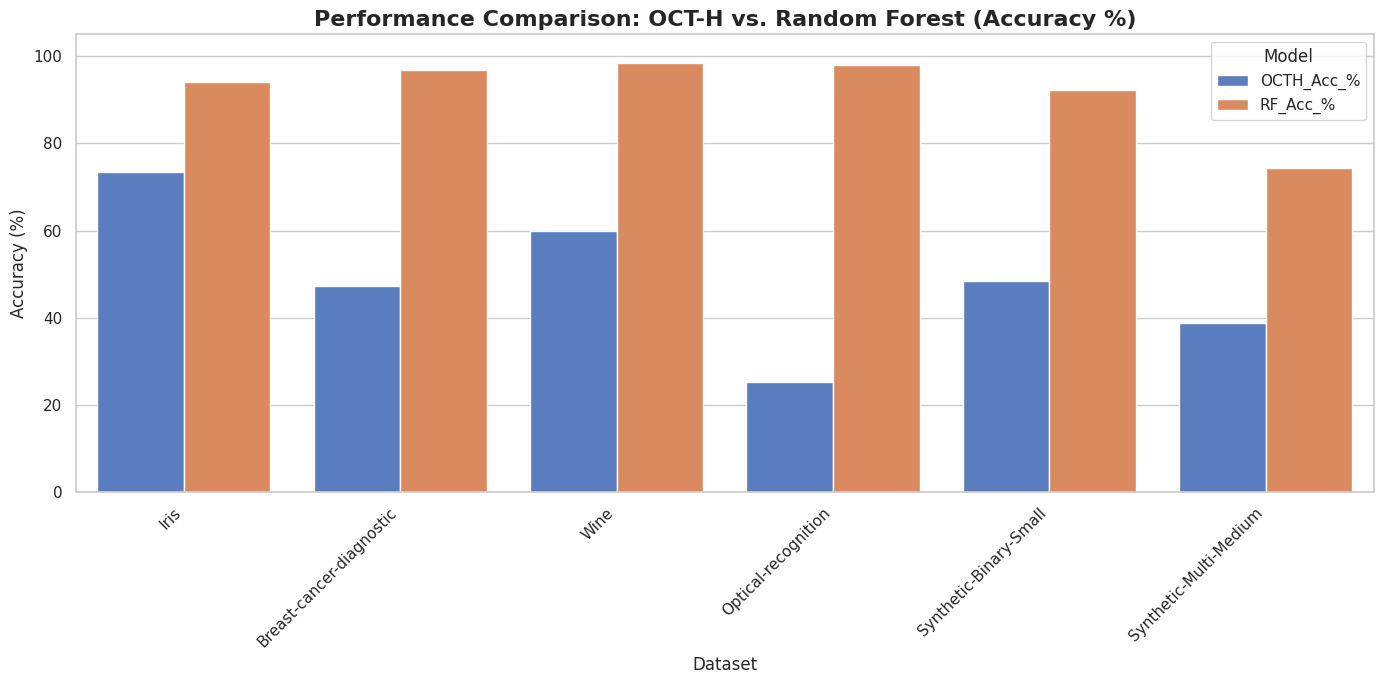

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Define results_df inside the global space if it hasn't been instantiated yet
try:
    if 'results_df' not in globals() or results_df is None:
        # Access via main function environment if possible, or fallback
        import __main__
        if hasattr(__main__, 'results_df') and __main__.results_df is not None:
            results_df = __main__.results_df
except Exception:
    pass

if results_df is not None and isinstance(results_df, pd.DataFrame):
    # Melt the results dataframe for side-by-side bar comparison
    plot_df = results_df.melt(
        id_vars=['Dataset', 'Diff_(OCTH-RF)'],
        value_vars=['OCTH_Acc_%', 'RF_Acc_%'],
        var_name='Model',
        value_name='Accuracy_%'
    )

    # Plotting
    plt.figure(figsize=(14, 7))
    sns.set_theme(style="whitegrid")

    ax = sns.barplot(
        data=plot_df,
        x='Dataset',
        y='Accuracy_%',
        hue='Model',
        palette='muted'
    )

    plt.title('Performance Comparison: OCT-H vs. Random Forest (Accuracy %)', fontsize=16, fontweight='bold')
    plt.xlabel('Dataset', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, 105)
    plt.legend(title='Model')
    plt.tight_layout()
    plt.show()
else:
    print("Please run cell XwxbRkwTlHK1 again to execute the updated main() function so that 'results_df' is populated globally.")